# 04 — Cluster composites

Single series from the previous notebook either sit on the fixed-price floor or jump around more than H100 on demand. This notebook builds baskets that can be more stable than a typical member, and that still exist when some members are missing.

**Distance.** For each eligible series, take the log change of its inverse index on adjacent days. Distance is \(1 - \mathrm{corr}\) of those changes. A pair needs 20 overlapping changes; otherwise the distance is treated as far.

**Clusters.** Average-linkage hierarchical clustering. The number of clusters is whichever of 2…8 has the best silhouette.

**Composite.** Inside a cluster, weight members by the inverse of their log-volatility. On a date when a member has no price, drop it and rescale the remaining weights to sum to 1. If fewer than three members are quoted, the composite is NA for that date. Clusters smaller than three do not get a composite.

A basket cannot become *more* stable than a series whose price never moves. That fixed-price floor is the baseline's own log-volatility. What a basket can do is average away idiosyncratic jumps, so the composite should land between the floor and the volatility of a typical member.


In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from icx.clusters import sync_clusters
from icx.indices import load_vector
from icx.runtime import require_project_venv
from icx.store import Decision, open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {layout.baseline.key}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND


In [2]:
membership_result, composite_result, stats_result = sync_clusters(layout)
membership = membership_result.frame
composites = composite_result.frame
stats = stats_result.frame
print(f"Membership: {membership_result.decision.value}  series={len(membership)}")
print(f"Composites: {composite_result.decision.value}  rows={len(composites)}")
print(f"Stats:      {stats_result.decision.value}")
again, _, _ = sync_clusters(layout)
print(f"Second:     {again.decision.value}")
if again.decision is not Decision.SKIP:
    raise RuntimeError("Unchanged scores should reuse the stored clusters.")
print()
print(stats.sort_values("composite_log_vol").to_string(index=False))
print()
print(membership.groupby("cluster").size().rename("series").to_string())


Membership: full  series=194
Composites: full  rows=264
Stats:      full
Second:     skip

 cluster  n_members  best_member_log_vol  median_member_log_vol  composite_log_vol  mean_members_present
       1        177             0.016781               0.141586           0.035874            173.500000
       0         17             0.077259               0.232518           0.110270             15.878788

cluster
0     17
1    177


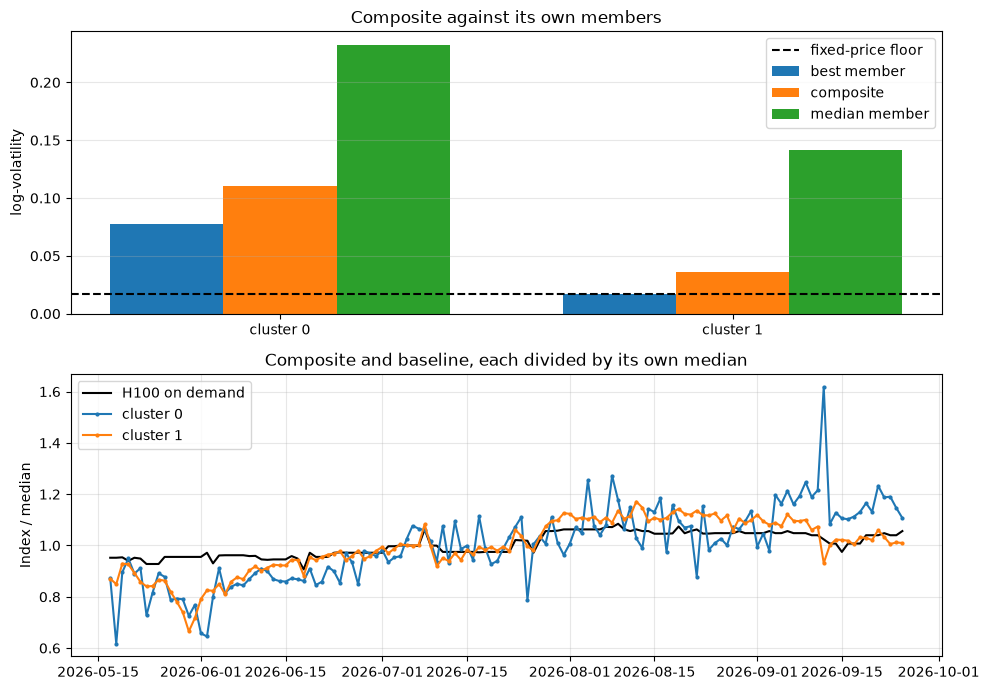

In [3]:
vector = load_vector(layout)
ordered = vector.sort_values("date")
baseline_vol = float(
    np.log(pd.to_numeric(ordered["index_value"])).diff().loc[
        pd.to_datetime(ordered["date"]).diff().dt.days.eq(1)
    ].std(ddof=1)
)

def normalized(dates, values) -> pd.DataFrame:
    frame = pd.DataFrame({"date": pd.to_datetime(dates), "value": pd.to_numeric(values)})
    frame = frame.dropna().sort_values("date")
    frame["value"] = frame["value"] / frame["value"].median()
    rows = []
    previous = None
    for row in frame.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "value": np.nan})
        rows.append({"date": row.date, "value": row.value})
        previous = row.date
    return pd.DataFrame(rows)

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
stats_plot = stats.dropna(subset=["composite_log_vol"]).sort_values("cluster")
x = np.arange(len(stats_plot))
width = 0.25
axes[0].bar(x - width, stats_plot["best_member_log_vol"], width, label="best member")
axes[0].bar(x, stats_plot["composite_log_vol"], width, label="composite")
axes[0].bar(x + width, stats_plot["median_member_log_vol"], width, label="median member")
axes[0].axhline(baseline_vol, color="black", ls="--", label="fixed-price floor")
axes[0].set_xticks(x, [f"cluster {int(c)}" for c in stats_plot["cluster"]])
axes[0].set_ylabel("log-volatility")
axes[0].set_title("Composite against its own members")
axes[0].legend()
axes[0].grid(True, axis="y", alpha=0.3)

base_line = normalized(ordered["date"], ordered["index_value"])
axes[1].plot(base_line["date"], base_line["value"], color="black", label="H100 on demand", lw=1.5)
for cluster, group in composites.groupby("cluster"):
    line = normalized(group["date"], group["index_value"])
    if line["value"].notna().sum() < 5:
        continue
    axes[1].plot(line["date"], line["value"], label=f"cluster {int(cluster)}", marker="o", ms=2)
axes[1].set_title("Composite and baseline, each divided by its own median")
axes[1].set_ylabel("Index / median")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
